# ETTデータを用いた変圧器オイル温度予測 PoC

## 目的
ETT（Electricity Transformer Temperature）データセットを用いて、変圧器のオイル温度 `OT` を将来予測し、予測結果が運用・予防保全判断にどの程度活用できるかを検証する。

## 本PoCで置く仮定
- 時刻 `t` までに観測可能な情報だけを入力に使用する。
- 将来時点の負荷情報は使用しない。
- 主分析は1時間粒度の `ETTh1` / `ETTh2` を用いる。
- 予測時間（horizon）は 1 / 3 / 6 / 12 / 24 時間先を評価する。
- データ分割は時系列順に Train 70% / Validation 15% / Test 15% とし、ランダム分割は行わない。

## 分析の流れ
1. データ品質確認
2. EDA
3. 特徴量設計
4. 候補モデル比較
5. 予測時間別の評価
6. PoCとしての結論・限界

## 1. ライブラリ

In [ ]:
from pathlib import Path
import importlib.util
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# XGBoost / LightGBM が未導入の場合のみインストール
if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
if importlib.util.find_spec("lightgbm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. データ読み込み

GitHub上では `data/`、Notebookを `notebooks/` から実行する場合は `../data/` を参照する。
ColabでCSVを直接アップロードした場合にも対応できるよう、複数候補を探索する。

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ETTh1.csv to ETTh1 (1).csv
Saving ETTh2.csv to ETTh2 (1).csv
Saving ETTm1.csv to ETTm1 (1).csv
Saving ETTm2.csv to ETTm2 (1).csv


## 3. データ品質確認

In [ ]:
quality_rows = []

for name, df in dfs.items():
    expected_minutes = 60 if name.startswith("ETTh") else 15
    intervals = df["date"].diff().dropna().dt.total_seconds() / 60

    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "missing": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_dates": int(df["date"].duplicated().sum()),
        "time_sorted": df["date"].is_monotonic_increasing,
        "median_interval_min": intervals.median(),
        "unexpected_intervals": int((intervals != expected_minutes).sum())
    })

quality_summary = pd.DataFrame(quality_rows)
quality_summary

,dataset,rows,columns,missing,duplicate_rows,duplicate_dates,time_sorted,median_interval_min,unexpected_intervals
0,ETTh1,17420,8,0,0,0,True,60.0000,0
1,ETTh2,17420,8,0,0,0,True,60.0000,0
2,ETTm1,69680,8,0,0,0,True,15.0000,0
3,ETTm2,69680,8,0,0,0,True,15.0000,0


### hourly と 15-minute データの関係
4ファイルを4台の設備と誤解しないため、`ETTh1 ↔ ETTm1`、`ETTh2 ↔ ETTm2` の対応だけ確認する。

In [ ]:
relation_rows = []
for h_name, m_name in [("ETTh1", "ETTm1"), ("ETTh2", "ETTm2")]:
    h = dfs[h_name].reset_index(drop=True)
    m_hour = dfs[m_name][dfs[m_name]["date"].dt.minute.eq(0)].reset_index(drop=True)
    numeric_cols = [c for c in h.columns if c != "date"]

    relation_rows.append({
        "pair": f"{h_name} / {m_name}",
        "dates_identical": h["date"].equals(m_hour["date"]),
        "max_abs_numeric_diff": (h[numeric_cols] - m_hour[numeric_cols]).abs().to_numpy().max()
    })

pd.DataFrame(relation_rows)

,pair,dates_identical,max_abs_numeric_diff
0,ETTh1 / ETTm1,True,0.0000
1,ETTh2 / ETTm2,True,0.0000


## 4. EDA

主分析は1時間粒度のETTh1 / ETTh2を対象とする。

### 4.1 OTの基本統計

In [ ]:
ot_stats = pd.concat(
    {name: dfs[name]["OT"].describe() for name in ["ETTh1", "ETTh2"]},
    axis=1
).T
ot_stats

,count,mean,std,min,25%,50%,75%,max
ETTh1,"17,420.0000",13.3247,8.5669,-4.0800,6.9640,11.3960,18.0790,46.0070
ETTh2,"17,420.0000",26.6094,11.8883,-2.6465,16.4695,26.5770,35.5860,58.8770


### 4.2 OTの時系列推移

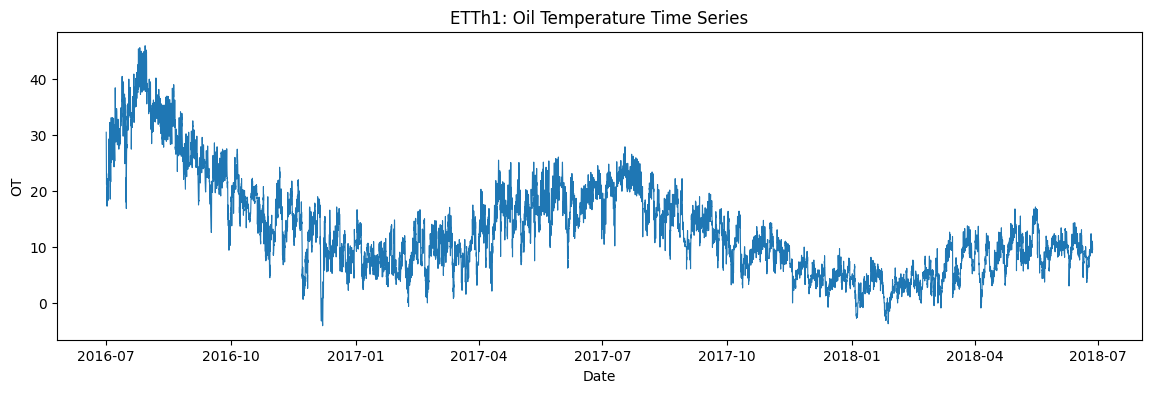

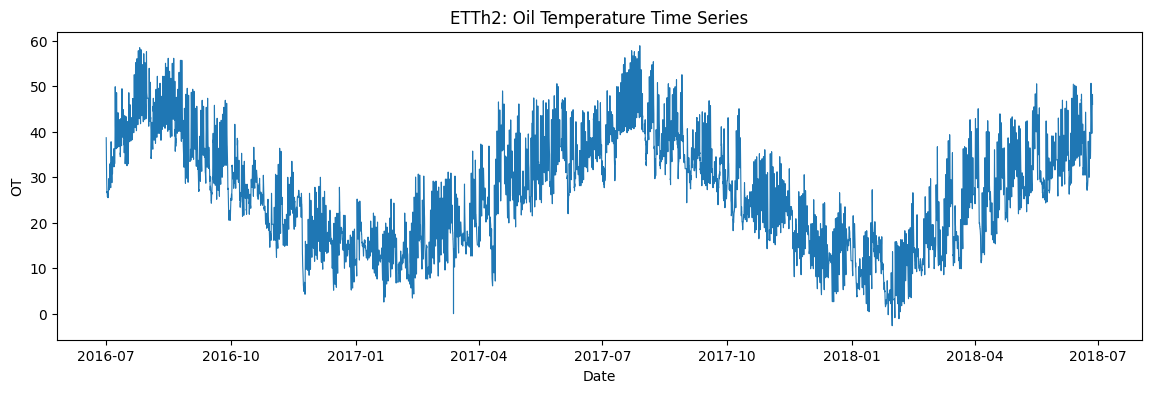

In [ ]:
for name in ["ETTh1", "ETTh2"]:
    df = dfs[name]
    plt.figure(figsize=(14, 4))
    plt.plot(df["date"], df["OT"], linewidth=0.8)
    plt.xlabel("Date")
    plt.ylabel("OT")
    plt.title(f"{name}: Oil Temperature Time Series")
    plt.show()

### 4.3 月別・時間帯別の平均OT


===== ETTh1: 月別平均OT =====


,mean_OT
month,
1,5.1690
2,6.1701
3,8.0254
4,11.8218
5,13.9411
6,14.0993
7,27.4201
8,23.6515
9,18.1739


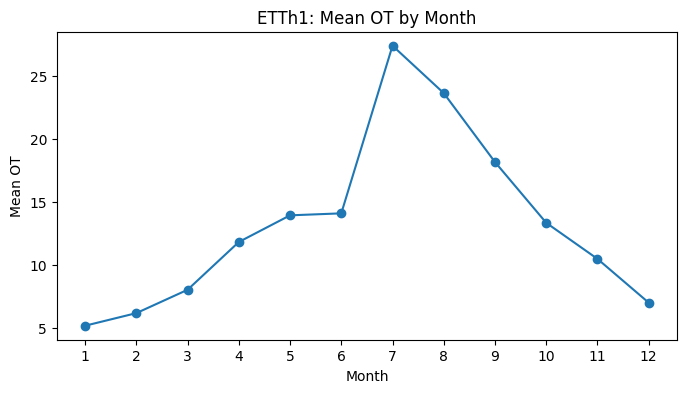

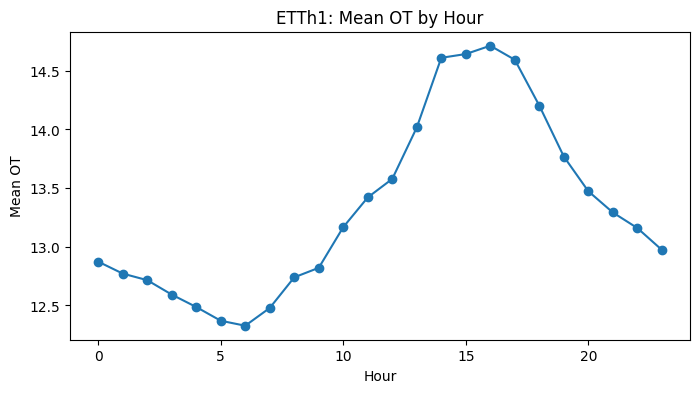


===== ETTh2: 月別平均OT =====


,mean_OT
month,
1,11.5776
2,13.4542
3,20.0689
4,27.6311
5,32.6902
6,36.2414
7,42.0293
8,41.1450
9,33.6012


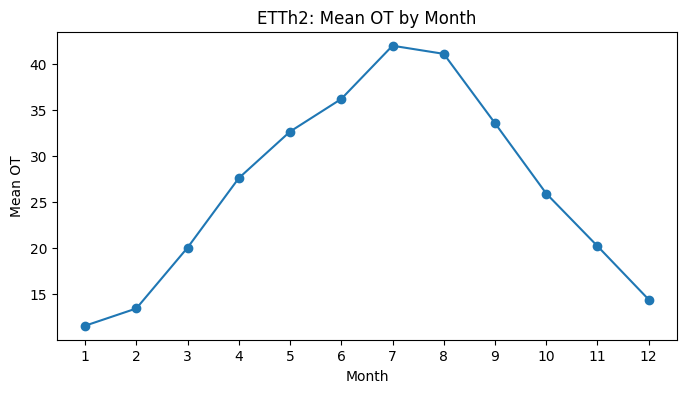

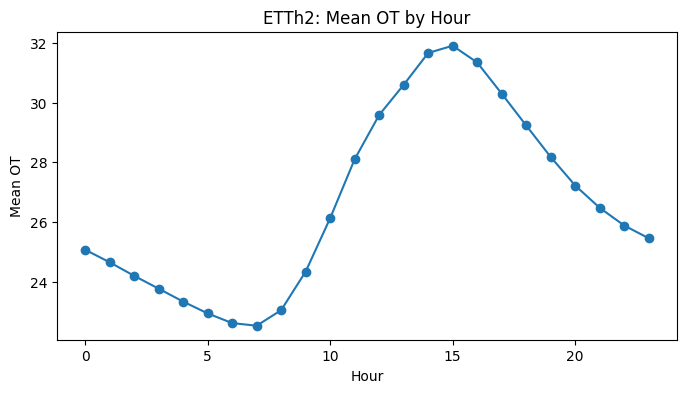

In [ ]:
for name in ["ETTh1", "ETTh2"]:
    df = dfs[name].copy()
    df["month"] = df["date"].dt.month
    df["hour"] = df["date"].dt.hour

    monthly = df.groupby("month")["OT"].mean()
    hourly = df.groupby("hour")["OT"].mean()

    print(f"\n===== {name}: 月別平均OT =====")
    display(monthly.to_frame("mean_OT"))

    plt.figure(figsize=(8, 4))
    plt.plot(monthly.index, monthly.values, marker="o")
    plt.xticks(range(1, 13))
    plt.xlabel("Month")
    plt.ylabel("Mean OT")
    plt.title(f"{name}: Mean OT by Month")
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(hourly.index, hourly.values, marker="o")
    plt.xlabel("Hour")
    plt.ylabel("Mean OT")
    plt.title(f"{name}: Mean OT by Hour")
    plt.show()

### 4.4 負荷特徴量とOTの線形相関

In [ ]:
load_cols = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]

corr_rows = []
for name in ["ETTh1", "ETTh2"]:
    corr = dfs[name][load_cols + ["OT"]].corr()["OT"].drop("OT")
    for feature, value in corr.items():
        corr_rows.append({"dataset": name, "feature": feature, "corr_with_OT": value})

corr_df = pd.DataFrame(corr_rows)
corr_df.pivot(index="feature", columns="dataset", values="corr_with_OT")

dataset,ETTh1,ETTh2
feature,,
HUFL,0.0599,0.0345
HULL,0.2244,0.3377
LUFL,0.1188,-0.1437
LULL,0.0675,-0.1121
MUFL,0.0509,0.1938
MULL,0.2200,0.4948


### 4.5 過去OTとの関係
短期予測で過去の温度履歴がどの程度有効か確認する。

In [ ]:
lags = [1, 3, 6, 12, 24, 168]
lag_rows = []

for name in ["ETTh1", "ETTh2"]:
    s = dfs[name]["OT"]
    for lag in lags:
        lag_rows.append({
            "dataset": name,
            "lag_hours": lag,
            "corr": s.corr(s.shift(lag))
        })

lag_corr = pd.DataFrame(lag_rows)
lag_corr.pivot(index="lag_hours", columns="dataset", values="corr")

dataset,ETTh1,ETTh2
lag_hours,,
1,0.9943,0.9941
3,0.9830,0.9601
6,0.9664,0.8874
12,0.9428,0.8129
24,0.9406,0.9342
168,0.8701,0.8281


## 5. 特徴量設計と評価方法

### 特徴量
- 現在OT
- 過去OT：1 / 3 / 6 / 24 / 168時間前
- 負荷6変数：HUFL, HULL, MUFL, MULL, LUFL, LULL
- 時間情報：hour / day of week / month を sin/cos で周期表現

### 評価指標
- MAE：平均的に何度ずれるか
- RMSE：大きな誤差をより重く評価
- R²：変動をどの程度説明できたか

モデル選択はValidationで行い、Testは最終確認だけに使用する。

In [ ]:
lag_cols = ["OT_lag1", "OT_lag3", "OT_lag6", "OT_lag24", "OT_lag168"]
time_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos"]

compact_features = ["OT"] + lag_cols
all_features = ["OT"] + lag_cols + load_cols + time_cols

feature_sets = {
    "Compact (OT + Lags)": compact_features,
    "All features": all_features
}

def make_horizon_data(df, horizon):
    data = df.copy().sort_values("date").reset_index(drop=True)

    data["hour"] = data["date"].dt.hour
    data["dayofweek"] = data["date"].dt.dayofweek
    data["month"] = data["date"].dt.month

    data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
    data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
    data["dow_sin"] = np.sin(2 * np.pi * data["dayofweek"] / 7)
    data["dow_cos"] = np.cos(2 * np.pi * data["dayofweek"] / 7)
    data["month_sin"] = np.sin(2 * np.pi * (data["month"] - 1) / 12)
    data["month_cos"] = np.cos(2 * np.pi * (data["month"] - 1) / 12)

    for lag in [1, 3, 6, 24, 168]:
        data[f"OT_lag{lag}"] = data["OT"].shift(lag)

    target_col = f"target_OT_{horizon}h"
    data[target_col] = data["OT"].shift(-horizon)

    return data.dropna().reset_index(drop=True), target_col

def time_split(data, train_ratio=0.70, val_ratio=0.15):
    n = len(data)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))
    return (
        data.iloc[:train_end].copy(),
        data.iloc[train_end:val_end].copy(),
        data.iloc[val_end:].copy()
    )

def calc_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

## 6. 候補モデル比較

### 比較対象
- **Naive Baseline**：未来OT = 現在OT（機械学習ではなく比較基準）
- **Linear Regression**：単純・説明可能な線形モデル
- **Random Forest**：非線形性・特徴量間相互作用を検証
- **XGBoost**：表形式データ向けBoostingモデル
- **LightGBM**：表形式データ向けBoostingモデル

1 / 6 / 24時間先で比較し、「複雑なモデルを使う価値があるか」を確認する。

In [ ]:
model_selection_horizons = [1, 6, 24]
model_selection_results = []

for dataset_name in ["ETTh1", "ETTh2"]:
    for horizon in model_selection_horizons:
        data_h, target_h = make_horizon_data(dfs[dataset_name], horizon)
        train, val, test = time_split(data_h)

        # Naive Baseline
        for split_name, split_df in [("Validation", val), ("Test", test)]:
            metrics = calc_metrics(split_df[target_h], split_df["OT"])
            model_selection_results.append({
                "dataset": dataset_name,
                "horizon_h": horizon,
                "model": "Naive Baseline",
                "feature_set": "Current OT",
                "split": split_name,
                **metrics
            })

        for feature_name, cols in feature_sets.items():
            candidates = {
                "Linear Regression": Pipeline([
                    ("scaler", StandardScaler()),
                    ("regressor", LinearRegression())
                ]),
                "Random Forest": RandomForestRegressor(
                    n_estimators=120, random_state=42, n_jobs=-1
                ),
                "XGBoost": XGBRegressor(
                    n_estimators=120, learning_rate=0.05, max_depth=5,
                    subsample=0.9, colsample_bytree=0.9,
                    objective="reg:squarederror",
                    random_state=42, n_jobs=-1
                ),
                "LightGBM": LGBMRegressor(
                    n_estimators=120, learning_rate=0.05,
                    num_leaves=31, subsample=0.9, colsample_bytree=0.9,
                    random_state=42, verbosity=-1
                )
            }

            for model_name, model in candidates.items():
                model.fit(train[cols], train[target_h])

                for split_name, split_df in [("Validation", val), ("Test", test)]:
                    pred = model.predict(split_df[cols])
                    metrics = calc_metrics(split_df[target_h], pred)
                    model_selection_results.append({
                        "dataset": dataset_name,
                        "horizon_h": horizon,
                        "model": model_name,
                        "feature_set": feature_name,
                        "split": split_name,
                        **metrics
                    })

model_selection_df = pd.DataFrame(model_selection_results)

validation_models = (
    model_selection_df[model_selection_df["split"] == "Validation"]
    .sort_values(["dataset", "horizon_h", "MAE"])
)

validation_models

,dataset,horizon_h,model,feature_set,split,MAE,RMSE,R2
0,ETTh1,1,Naive Baseline,Current OT,Validation,0.4261,0.5958,0.9287
2,ETTh1,1,Linear Regression,Compact (OT + Lags),Validation,0.4305,0.5933,0.9293
10,ETTh1,1,Linear Regression,All features,Validation,0.4489,0.6080,0.9258
8,ETTh1,1,LightGBM,Compact (OT + Lags),Validation,0.5118,0.6836,0.9062
16,ETTh1,1,LightGBM,All features,Validation,0.5288,0.7014,0.9013
4,ETTh1,1,Random Forest,Compact (OT + Lags),Validation,0.5454,0.7114,0.8984
14,ETTh1,1,XGBoost,All features,Validation,0.5502,0.7613,0.8837
6,ETTh1,1,XGBoost,Compact (OT + Lags),Validation,0.5528,0.7344,0.8917
12,ETTh1,1,Random Forest,All features,Validation,0.5737,0.7493,0.8873
18,ETTh1,6,Naive Baseline,Current OT,Validation,1.0437,1.3850,0.6153


### モデル選択の要点
Validationでは、Random Forest / XGBoost / LightGBMはLinear Regressionを一貫して上回らなかった。
そのため、**精度・説明性・再現性・実装の簡潔さ**を総合し、主モデルとしてLinear Regressionを採用する。

ただしETTh1の短期ではNaive Baselineが非常に強く、機械学習が必ずしも有効とは限らないことも結果として重視する。

## 7. 予測可能時間の境界評価

Linear RegressionとNaive Baselineに絞り、
1 / 3 / 6 / 12 / 24時間先を評価する。

各horizonで、ValidationのMAEが最も小さい構成を選び、Testで最終性能を確認する。

In [ ]:
boundary_horizons = [1, 3, 6, 12, 24]
boundary_results = []

for dataset_name in ["ETTh1", "ETTh2"]:
    for horizon in boundary_horizons:
        data_h, target_h = make_horizon_data(dfs[dataset_name], horizon)
        train, val, test = time_split(data_h)

        # Baseline
        for split_name, split_df in [("Validation", val), ("Test", test)]:
            metrics = calc_metrics(split_df[target_h], split_df["OT"])
            boundary_results.append({
                "dataset": dataset_name,
                "horizon_h": horizon,
                "model": "Naive Baseline",
                "feature_set": "Current OT",
                "split": split_name,
                **metrics
            })

        # Linear Regression
        for feature_name, cols in feature_sets.items():
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("regressor", LinearRegression())
            ])
            model.fit(train[cols], train[target_h])

            for split_name, split_df in [("Validation", val), ("Test", test)]:
                pred = model.predict(split_df[cols])
                metrics = calc_metrics(split_df[target_h], pred)
                boundary_results.append({
                    "dataset": dataset_name,
                    "horizon_h": horizon,
                    "model": "Linear Regression",
                    "feature_set": feature_name,
                    "split": split_name,
                    **metrics
                })

boundary_df = pd.DataFrame(boundary_results)

validation_boundary = boundary_df[boundary_df["split"] == "Validation"]
best_configs = (
    validation_boundary
    .sort_values("MAE")
    .groupby(["dataset", "horizon_h"], as_index=False)
    .first()
)

best_test_rows = []
for _, row in best_configs.iterrows():
    match = boundary_df[
        (boundary_df["dataset"] == row["dataset"]) &
        (boundary_df["horizon_h"] == row["horizon_h"]) &
        (boundary_df["model"] == row["model"]) &
        (boundary_df["feature_set"] == row["feature_set"]) &
        (boundary_df["split"] == "Test")
    ]
    best_test_rows.append(match)

best_test = pd.concat(best_test_rows, ignore_index=True)

baseline_test = (
    boundary_df[
        (boundary_df["split"] == "Test") &
        (boundary_df["model"] == "Naive Baseline")
    ][["dataset", "horizon_h", "MAE"]]
    .rename(columns={"MAE": "baseline_MAE"})
)

final_compare = best_test.merge(
    baseline_test, on=["dataset", "horizon_h"], how="left"
)

final_compare["MAE_improvement_rate_%"] = (
    (final_compare["baseline_MAE"] - final_compare["MAE"])
    / final_compare["baseline_MAE"]
    * 100
)

final_table = final_compare[
    [
        "dataset", "horizon_h", "model", "feature_set",
        "baseline_MAE", "MAE", "MAE_improvement_rate_%", "RMSE", "R2"
    ]
].sort_values(["dataset", "horizon_h"])

final_table

,dataset,horizon_h,model,feature_set,baseline_MAE,MAE,MAE_improvement_rate_%,RMSE,R2
0,ETTh1,1,Naive Baseline,Current OT,0.4441,0.4441,0.0000,0.6585,0.9461
1,ETTh1,3,Naive Baseline,Current OT,0.8280,0.8280,0.0000,1.1796,0.8270
2,ETTh1,6,Naive Baseline,Current OT,1.2425,1.2425,0.0000,1.6680,0.6542
3,ETTh1,12,Linear Regression,Compact (OT + Lags),1.6598,1.5198,8.4358,1.9988,0.5035
4,ETTh1,24,Linear Regression,All features,1.6999,1.8551,-9.1329,2.5085,0.2181
5,ETTh2,1,Linear Regression,Compact (OT + Lags),0.9948,0.5671,42.9951,0.8082,0.9905
6,ETTh2,3,Linear Regression,All features,2.7713,1.5933,42.5065,2.1594,0.9321
7,ETTh2,6,Linear Regression,All features,4.8632,2.8110,42.1989,3.7756,0.7922
8,ETTh2,12,Linear Regression,All features,6.8031,3.3984,50.0465,4.4539,0.7106
9,ETTh2,24,Linear Regression,All features,3.6606,3.6689,-0.2276,4.6343,0.6865


### 予測時間とBaseline改善率

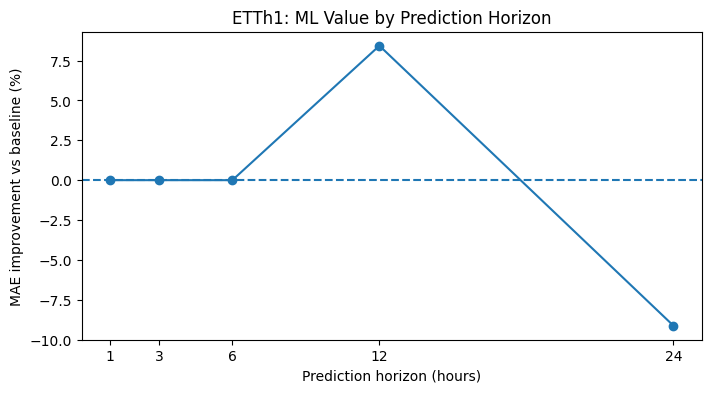

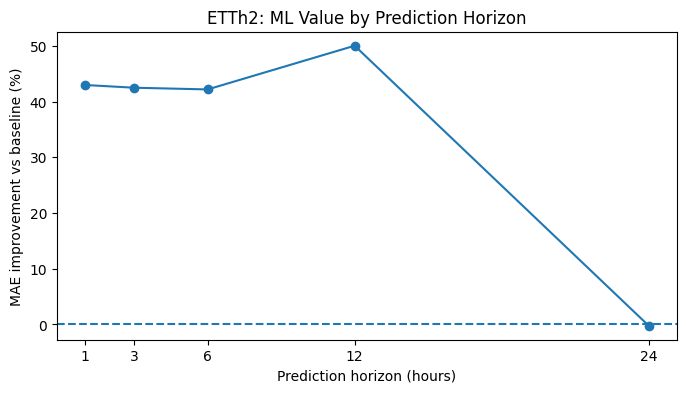

In [ ]:
for dataset in ["ETTh1", "ETTh2"]:
    tmp = final_table[final_table["dataset"] == dataset].sort_values("horizon_h")

    plt.figure(figsize=(8, 4))
    plt.plot(tmp["horizon_h"], tmp["MAE_improvement_rate_%"], marker="o")
    plt.axhline(0, linestyle="--")
    plt.xticks(boundary_horizons)
    plt.xlabel("Prediction horizon (hours)")
    plt.ylabel("MAE improvement vs baseline (%)")
    plt.title(f"{dataset}: ML Value by Prediction Horizon")
    plt.show()

## 8. 最終結果の解釈

今回の実行結果では、以下が確認された。

### Transformer 1（ETTh1）
- 1 / 3 / 6時間先ではNaive Baselineが最良。
- 12時間先ではLinear RegressionがBaselineを約8%改善。
- 24時間先ではLinear RegressionがBaselineより悪化。
- 短期予測では現在OTの継続性が非常に強く、機械学習の追加価値は限定的。

### Transformer 2（ETTh2）
- 1時間先：約43%改善
- 3時間先：約43%改善
- 6時間先：約42%改善
- 12時間先：約50%改善
- 24時間先：Baselineとほぼ同等
- したがって、**少なくとも12時間先まではLinear Regressionによる明確な追加価値が確認された**。

### モデル選定
Random Forest / XGBoost / LightGBMも実装・比較したが、ValidationでLinear Regressionを安定して上回らなかった。
よって、精度に加えて説明性・再現性・実装の簡潔さを考慮し、Linear Regressionを主モデルとして採用する。

## 9. PoCとしての業務価値

- **1〜3時間先**：直近監視・早期警戒への活用候補
- **6〜12時間先**：当日中の点検優先順位や運用判断への活用候補
- **24時間先**：現状モデルでは明確な改善がなく、翌日単位の保全計画には追加改善が必要

重要なのは、設備によってモデルの価値が異なる点である。
Transformer 1では単純予測が強く、Transformer 2では機械学習による明確な改善が見られた。

## 10. 限界と今後の改善

### 限界
- ETT内の変数だけを利用しており、外気温・天候・保全履歴などを含んでいない。
- Transformer 1 / 2で予測特性が異なる。
- 一部評価期間では高温サンプルが少なく、高温時性能を十分に評価できない。
- 24時間先ではBaselineを明確に上回れない。

### 今後
- 外気温・気象データ等の追加
- 設備別モデルの最適化
- 時系列Cross Validationによる安定性確認
- 高温イベントの分類・早期警戒モデルの追加
- 24時間以上の予測が必要な場合、専用時系列モデルの検討